# SpaceFuzz data analysis A1-A4

Plan section 2.5. Each analysis produces one figure (saved to `notebooks/figures/`) and a
set of numbers. The final cell collects the numbers that become constants in `config.py`;
every constant there names the analysis it came from.

Data is read through the project loaders (`env_trace`, `physio_replay`, `generic_reader`),
so the same unit conversions, ISS-only columns and time-weighting apply as in the engine.

In [1]:
import json
import logging
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
logging.disable(logging.WARNING)   # gap warnings from env_trace.clip are expected here

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from spacefuzz import config
from spacefuzz.readers import env_trace as et
from spacefuzz.readers import generic_reader as gr
from spacefuzz.readers import physio_replay as pr

FIG = ROOT / "notebooks" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
RESULTS = {}


def to_time(trace, start):
    """Minute-indexed trace -> timestamp index (for plotting and daily grouping)."""
    out = trace.copy()
    out.index = pd.Timestamp(start) + pd.to_timedelta(out.index, unit="min")
    return out

## A1 Cabin CO2, temperature and humidity: daily pattern and high periods (EDA RR-1, ISS)

Only `*_ISS` columns, and only from `config.EDA_ISS_START`. The data quality gate's stuck
detection (`quality_gate.stuck_mask`, CO2 limit 120 min) finds CO2 frozen at exactly
2646 ppm from 2014-09-21 04:24 to 09-27 13:25 (153 h; normal days never stay unchanged for
more than 75 min). That window matches the RR-1 delivery: the mice flew on SpaceX CRS-4
(launch 2014-09-21 05:52 UTC, berthed 2014-09-23 13:21 UTC) and were then moved into the
station. The check figure below shows temperature swinging by 8 degC and humidity up to
76% during launch and transit, then a warm, dry plateau until CO2 resumes; from 09-27
13:30 all three variables look like the rest of the record. So everything before that
point (from the first reading on 09-20, when the mice were on the pad) is not ISS cabin
air and is excluded for all variables; env_trace applies the same cut. The installation
time itself is inferred from the data, not from a mission log.

Days with less than half a day of CO2 are left out of the daily statistics. Series are
15-minute time-weighted means (same as the engine's environment trace).

- **Operator B amplitude**: how far a day's peak rises above that day's median CO2,
  `daily max / daily median - 1`. The usual range is P25-P90 across days; the upper bound
  is the observed maximum, because the rare high days are real and fuzzing must reach them.
  The per-day values are saved as the sampling pool, so operator B draws by observed
  frequency: mostly 11-23%, with a real tail up to the maximum.
- **High CO2 threshold**: P90 of all 15-minute values; contiguous runs above it are high periods.
- **High CO2 day**: the day with the highest mean CO2, for the backup scenario.

In [2]:
from spacefuzz.core import quality_gate as qg

ENV_MAP = ROOT / "data" / "mappings" / "env_telemetry.yaml"
raw = gr.read_source(ENV_MAP, "eda_rr1")             # uncut, to locate the frozen run
raw_minutes = (raw["timestamp"] - raw["timestamp"].iloc[0]).dt.total_seconds() / 60
stuck = qg.stuck_mask(raw["co2"], raw_minutes, config.QG_STUCK_MINUTES["co2"])
stuck_span = [str(raw.loc[stuck, "timestamp"].min()), str(raw.loc[stuck, "timestamp"].max())]
iss_start = raw.loc[raw["timestamp"] > raw.loc[stuck, "timestamp"].max(), "timestamp"].min()
LAUNCH, BERTH = pd.Timestamp("2014-09-21 05:52"), pd.Timestamp("2014-09-23 13:21")

eda = raw[raw["timestamp"] >= iss_start].reset_index(drop=True)
eda_minutes = (eda["timestamp"] - eda["timestamp"].iloc[0]).dt.total_seconds() / 60
later_stuck = qg.stuck_mask(eda["co2"], eda_minutes, config.QG_STUCK_MINUTES["co2"])
eda.loc[later_stuck, "co2"] = np.nan                 # none expected after installation
a1_start = eda["timestamp"].min().normalize()
a1_hours = (eda["timestamp"].max() - a1_start) / pd.Timedelta(hours=1) + 1
cabin = to_time(et.clip(eda, a1_start, a1_hours), a1_start).dropna(how="all")

co2 = cabin["co2"].dropna()
steps_per_day = co2.groupby(co2.index.normalize()).size()
full_days = steps_per_day[steps_per_day >= config.STEPS_PER_DAY // 2].index
co2_days = co2[co2.index.normalize().isin(full_days)]
by_day = co2_days.groupby(co2_days.index.normalize())
excursion = by_day.max() / by_day.median() - 1
co2_high = co2.quantile(0.90)
above = co2 > co2_high
run_id = (above != above.shift()).cumsum()
episodes = above.groupby(run_id).agg(["first", "size"])
episode_h = episodes.loc[episodes["first"], "size"] * config.STEP_MINUTES / 60
hourly = cabin.groupby(cabin.index.hour).quantile([0.1, 0.5, 0.9]).unstack()
high_day = by_day.mean().idxmax()

pre = raw[raw["timestamp"] < iss_start]
a1 = {
    "co2_stuck_excluded": stuck_span,
    "co2_stuck_readings": int(stuck.sum()),
    "pre_iss_excluded": [str(raw["timestamp"].min()), str(iss_start)],
    "pre_iss_temp_c_min_max_sd": [pre["temp"].min(), pre["temp"].max(), round(pre["temp"].std(), 2)],
    "pre_iss_rh_pct_min_max_sd": [pre["humidity"].min(), pre["humidity"].max(),
                                  round(pre["humidity"].std(), 2)],
    "iss_temp_c_sd": round(eda["temp"].std(), 2),
    "iss_rh_pct_sd": round(eda["humidity"].std(), 2),
    "stuck_after_installation": int(later_stuck.sum()),
    "days_used": int(by_day.ngroups),
    "co2_ppm_p05_p50_p95": [round(co2.quantile(q)) for q in (0.05, 0.5, 0.95)],
    "co2_high_ppm_p90": round(co2_high),
    "co2_hour_lowest_highest_median": [int(hourly[("co2", 0.5)].idxmin()),
                                      int(hourly[("co2", 0.5)].idxmax())],
    "daily_peak_excursion_p25_p50_p90": [round(excursion.quantile(q), 3) for q in (0.25, 0.5, 0.9)],
    "daily_peak_excursion_max": round(excursion.max(), 3),
    "share_of_days_in_p25_p90": round(excursion.between(excursion.quantile(0.25),
                                                        excursion.quantile(0.9)).mean(), 3),
    "high_periods": int(len(episode_h)),
    "high_period_hours_median_p90_max": [round(episode_h.median(), 2),
                                         round(episode_h.quantile(0.9), 2), round(episode_h.max(), 2)],
    "high_co2_day": str(high_day.date()),
    "high_co2_day_mean_max_ppm": [round(by_day.mean()[high_day]), round(by_day.max()[high_day])],
    "temp_c_p05_p95": [round(cabin["temp"].quantile(q), 2) for q in (0.05, 0.95)],
    "humidity_pct_p05_p95": [round(cabin["humidity"].quantile(q), 1) for q in (0.05, 0.95)],
}
EXCURSIONS_PATH = ROOT / "data" / "processed" / "op_b_co2_excursions.csv"
pd.DataFrame({"date": [d.date() for d in excursion.index],
              "excursion": excursion.round(3).values}).to_csv(EXCURSIONS_PATH, index=False)
RESULTS["A1"] = a1
a1

{'co2_stuck_excluded': ['2014-09-21 04:24:00', '2014-09-27 13:25:00'],
 'co2_stuck_readings': 1837,
 'pre_iss_excluded': ['2014-09-20 03:59:00', '2014-09-27 13:30:00'],
 'pre_iss_temp_c_min_max_sd': [np.float64(18.5),
  np.float64(26.8),
  np.float64(1.45)],
 'pre_iss_rh_pct_min_max_sd': [np.float64(31.0),
  np.float64(76.0),
  np.float64(14.86)],
 'iss_temp_c_sd': np.float64(0.26),
 'iss_rh_pct_sd': np.float64(2.92),
 'stuck_after_installation': 0,
 'days_used': 34,
 'co2_ppm_p05_p50_p95': [2134, 3385, 4161],
 'co2_high_ppm_p90': 3997,
 'co2_hour_lowest_highest_median': [8, 19],
 'daily_peak_excursion_p25_p50_p90': [np.float64(0.112),
  np.float64(0.144),
  np.float64(0.23)],
 'daily_peak_excursion_max': np.float64(0.403),
 'share_of_days_in_p25_p90': np.float64(0.618),
 'high_periods': 21,
 'high_period_hours_median_p90_max': [np.float64(1.0),
  np.float64(9.75),
  np.float64(17.75)],
 'high_co2_day': '2014-10-07',
 'high_co2_day_mean_max_ppm': [4219, 4663],
 'temp_c_p05_p95': [np.fl

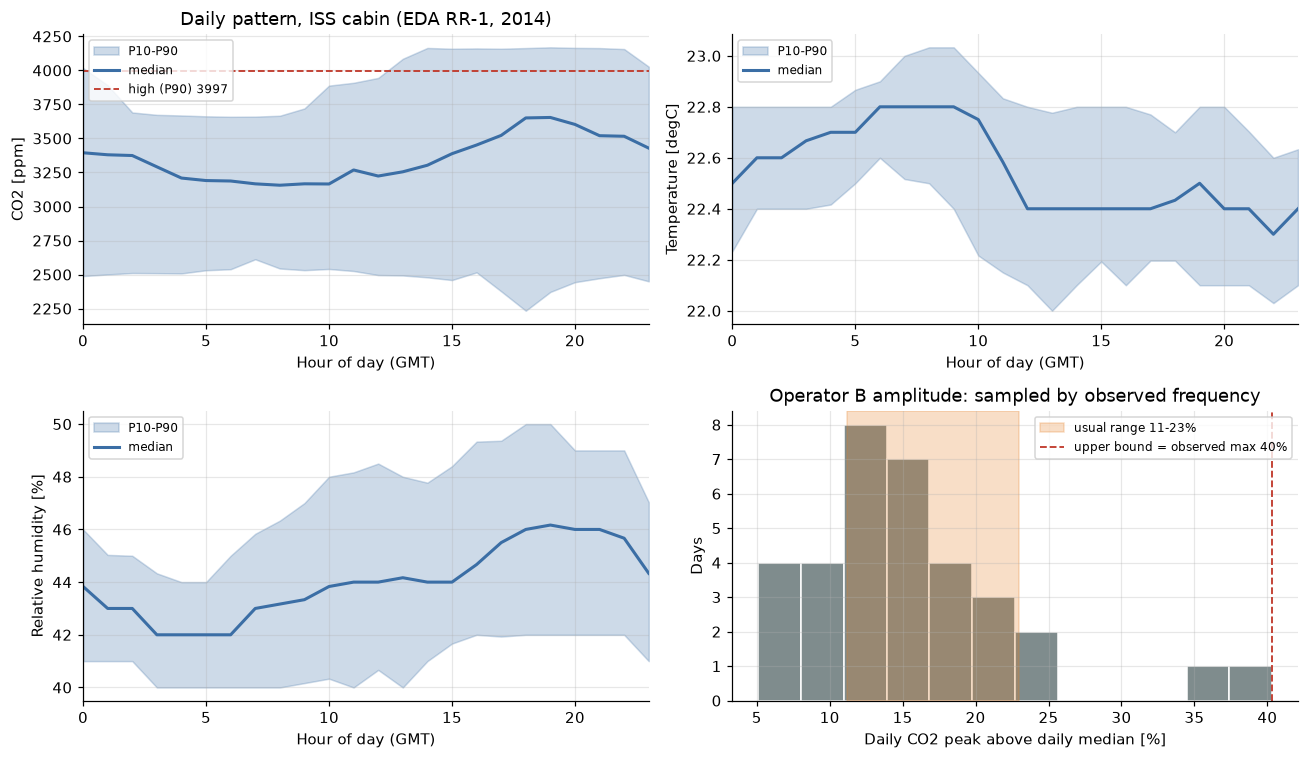

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (col, label) in zip(axes.flat[:3], [("co2", "CO2 [ppm]"), ("temp", "Temperature [degC]"),
                                           ("humidity", "Relative humidity [%]")]):
    ax.fill_between(hourly.index, hourly[(col, 0.1)], hourly[(col, 0.9)], alpha=0.25,
                    color="#3b6ea5", label="P10-P90")
    ax.plot(hourly.index, hourly[(col, 0.5)], color="#3b6ea5", lw=2, label="median")
    ax.set(xlabel="Hour of day (GMT)", ylabel=label, xlim=(0, 23))
    if col == "co2":
        ax.axhline(co2_high, color="#c0392b", ls="--", lw=1.2, label=f"high (P90) {co2_high:.0f}")
    ax.legend(loc="upper left", fontsize=8)
axes[0, 0].set_title("Daily pattern, ISS cabin (EDA RR-1, 2014)")
ax = axes[1, 1]
ax.hist(excursion * 100, bins=12, color="#7f8c8d", edgecolor="white")
lo, hi = excursion.quantile(0.25) * 100, excursion.quantile(0.9) * 100
ax.axvspan(lo, hi, color="#e67e22", alpha=0.25, label=f"usual range {lo:.0f}-{hi:.0f}%")
ax.axvline(excursion.max() * 100, color="#c0392b", ls="--", lw=1.2,
           label=f"upper bound = observed max {excursion.max() * 100:.0f}%")
ax.set(xlabel="Daily CO2 peak above daily median [%]", ylabel="Days",
       title="Operator B amplitude: sampled by observed frequency")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "A1_cabin_co2_temp_humidity.png")

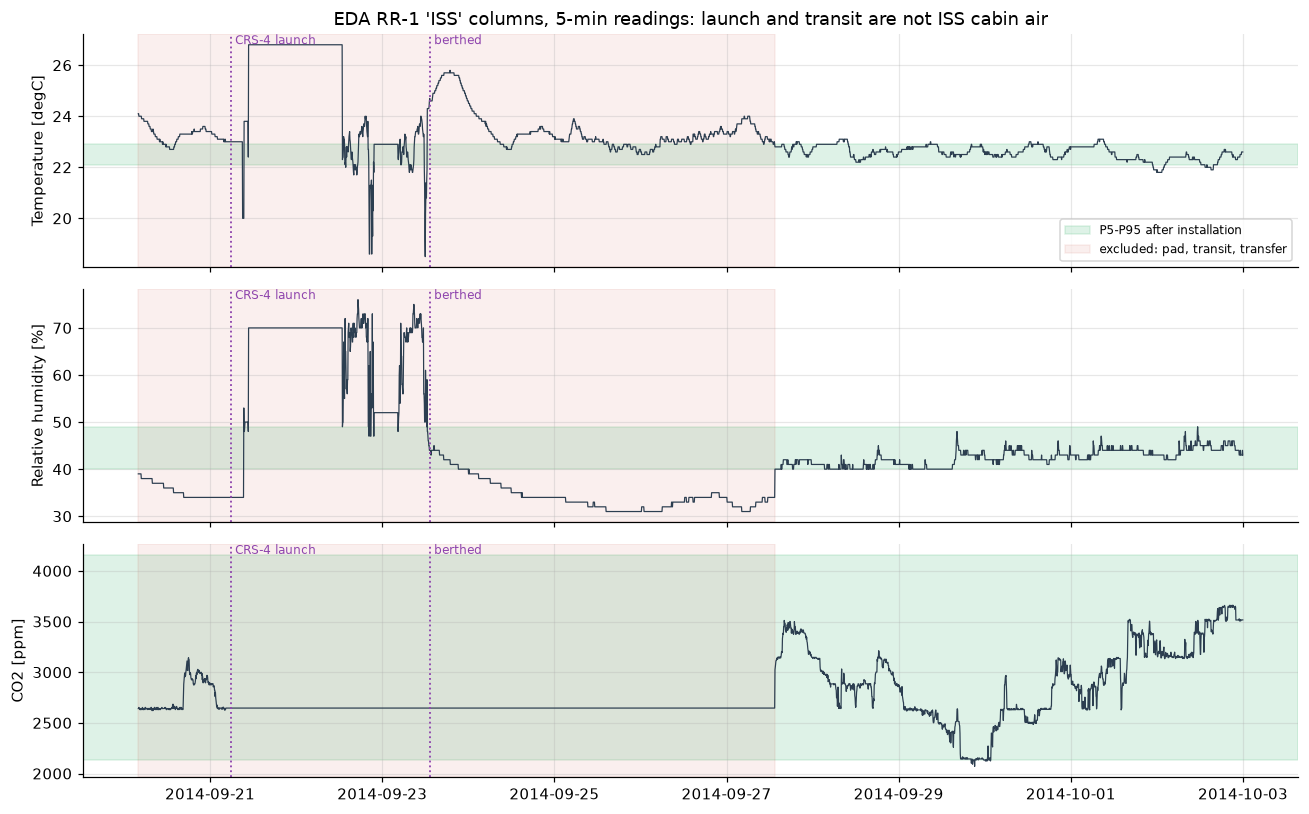

In [4]:
win = raw[raw["timestamp"] < "2014-10-03"]
normal = eda.set_index("timestamp")[["temp", "humidity", "co2"]]
fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True)
for ax, (col, label) in zip(axes, [("temp", "Temperature [degC]"), ("humidity", "Relative humidity [%]"),
                                   ("co2", "CO2 [ppm]")]):
    lo, hi = normal[col].quantile([0.05, 0.95])
    ax.axhspan(lo, hi, color="#27ae60", alpha=0.15, label="P5-P95 after installation")
    ax.plot(win["timestamp"], win[col], color="#2c3e50", lw=0.8)
    ax.axvspan(win["timestamp"].min(), iss_start, color="#c0392b", alpha=0.08,
               label="excluded: pad, transit, transfer")
    for t, name in ((LAUNCH, "CRS-4 launch"), (BERTH, "berthed")):
        ax.axvline(t, color="#8e44ad", ls=":", lw=1.2)
        ax.text(t, ax.get_ylim()[1], f" {name}", fontsize=8, va="top", color="#8e44ad")
    ax.set(ylabel=label)
axes[0].legend(loc="lower right", fontsize=8)
axes[0].set_title("EDA RR-1 'ISS' columns, 5-min readings: launch and transit are not ISS cabin air")
fig.tight_layout()
fig.savefig(FIG / "A1_check_rr1_transit.png")

## A2 Radiation dose rate and solar event peak multiples (RadLab DosTel2, MSL-RAD, GOES-16)

Window 2017-09-04..18. Dose rates are 15-minute time-weighted means in uGy/h; GOES XRS-B
flux keeps `xrsb_flag == 0` only (eclipse gaps stay empty).

- **ISS (DosTel2)**: quiet baseline = median of 15-minute bins; the South Atlantic Anomaly
  passes give the peak multiple (P99 / median).
- **Mars surface (MSL-RAD)**: baseline = median before the 2017-09-10 X-class flare; the
  solar particle event (SPE) is the stretch above 1.25x baseline after the flare. Its
  shape is saved for operator D (`superimpose`).
- **Lead time**: from the GOES flare peak to the SPE onset at Mars.

Flare class note: the officially issued classes are X9.3 (2017-09-06) and X8.2
(2017-09-10). GOES-16 science flux x 0.7 gives about 10% more; the catalog / science ratio
is 0.635 for both flares. Quote the catalog class in public material.

In [5]:
A2_START, A2_HOURS = "2017-09-04", 15 * 24
dos = to_time(et.clip(et.load_source("radlab_dostel2"), A2_START, A2_HOURS), A2_START)["dose_rate"]
msl = to_time(et.clip(et.load_source("radlab_msl_rad"), A2_START, A2_HOURS), A2_START)["dose_rate"]
goes = et.load_goes_xrsb(A2_START, "2017-09-19")

iss_base = dos.median()
mars_base = msl[:"2017-09-10 12:00"].median()
flare_peak_t = goes["2017-09-10"].idxmax()
after = msl[flare_peak_t:"2017-09-15"]
in_spe = after > 1.25 * mars_base
spe_on = in_spe[in_spe].index.min()
spe_off = in_spe[in_spe].index.max() + pd.Timedelta(minutes=config.STEP_MINUTES)
spe = msl[spe_on:spe_off - pd.Timedelta(minutes=1)]
iss_daily = dos.groupby(dos.index.normalize()).mean()

a2 = {
    "iss_baseline_ugy_h_median": round(iss_base, 2),
    "iss_mean_ugy_h_time_weighted": round(dos.mean(), 2),
    "iss_saa_peak_multiple_p99": round(dos.quantile(0.99) / iss_base, 1),
    "iss_saa_peak_multiple_max": round(dos.max() / iss_base, 1),
    "iss_daily_mean_max_over_median": round(iss_daily.max() / iss_daily.median(), 2),
    "mars_baseline_ugy_h": round(mars_base, 2),
    "flares": {str(d.date()): {"peak_utc": str(goes[str(d.date())].idxmax()),
                               "flux_w_m2": float(f"{goes[str(d.date())].max():.4g}"),
                               "official_class": et.flare_class(goes[str(d.date())].max())}
               for d in pd.to_datetime(["2017-09-06", "2017-09-10"])},
    "catalog_class": {"2017-09-06": "X9.3", "2017-09-10": "X8.2"},
    "catalog_over_science_flux": {d: round(c / goes[d].max(), 3)
                                  for d, c in (("2017-09-06", 9.3e-4), ("2017-09-10", 8.2e-4))},
    "spe_onset_utc": str(spe_on),
    "spe_end_utc": str(spe_off),
    "spe_duration_h": round((spe_off - spe_on) / pd.Timedelta(hours=1), 1),
    "flare_peak_to_spe_onset_h": round((spe_on - flare_peak_t) / pd.Timedelta(hours=1), 1),
    "spe_peak_multiple": round(spe.max() / mars_base, 2),
    "spe_plateau_multiple_median": round(spe.median() / mars_base, 2),
    "mars_post_event_ratio_09_13_on": round(msl["2017-09-13 06:00":].median() / mars_base, 3),
}

profile = (spe / mars_base - 1).round(4)
profile = pd.DataFrame({"minute": ((profile.index - spe_on) / pd.Timedelta(minutes=1)).astype(int),
                        "excess_over_baseline": profile.values})
PROFILE_PATH = ROOT / "data" / "processed" / "spe_profile_msl_rad.csv"
profile.to_csv(PROFILE_PATH, index=False)
a2["spe_profile_steps"] = len(profile)
RESULTS["A2"] = a2
a2

{'iss_baseline_ugy_h_median': np.float64(4.94),
 'iss_mean_ugy_h_time_weighted': np.float64(8.86),
 'iss_saa_peak_multiple_p99': np.float64(21.7),
 'iss_saa_peak_multiple_max': np.float64(38.6),
 'iss_daily_mean_max_over_median': np.float64(1.23),
 'mars_baseline_ugy_h': np.float64(7.79),
 'flares': {'2017-09-06': {'peak_utc': '2017-09-06 12:02:00',
   'flux_w_m2': 0.001464,
   'official_class': 'X9.3'},
  '2017-09-10': {'peak_utc': '2017-09-10 16:06:00',
   'flux_w_m2': 0.001292,
   'official_class': 'X8.2'}},
 'catalog_class': {'2017-09-06': 'X9.3', '2017-09-10': 'X8.2'},
 'catalog_over_science_flux': {'2017-09-06': np.float32(0.635),
  '2017-09-10': np.float32(0.635)},
 'spe_onset_utc': '2017-09-11 05:00:00',
 'spe_end_utc': '2017-09-13 04:00:00',
 'spe_duration_h': 47.0,
 'flare_peak_to_spe_onset_h': 12.9,
 'spe_peak_multiple': np.float64(2.98),
 'spe_plateau_multiple_median': np.float64(1.88),
 'mars_post_event_ratio_09_13_on': np.float64(0.885),
 'spe_profile_steps': 188}

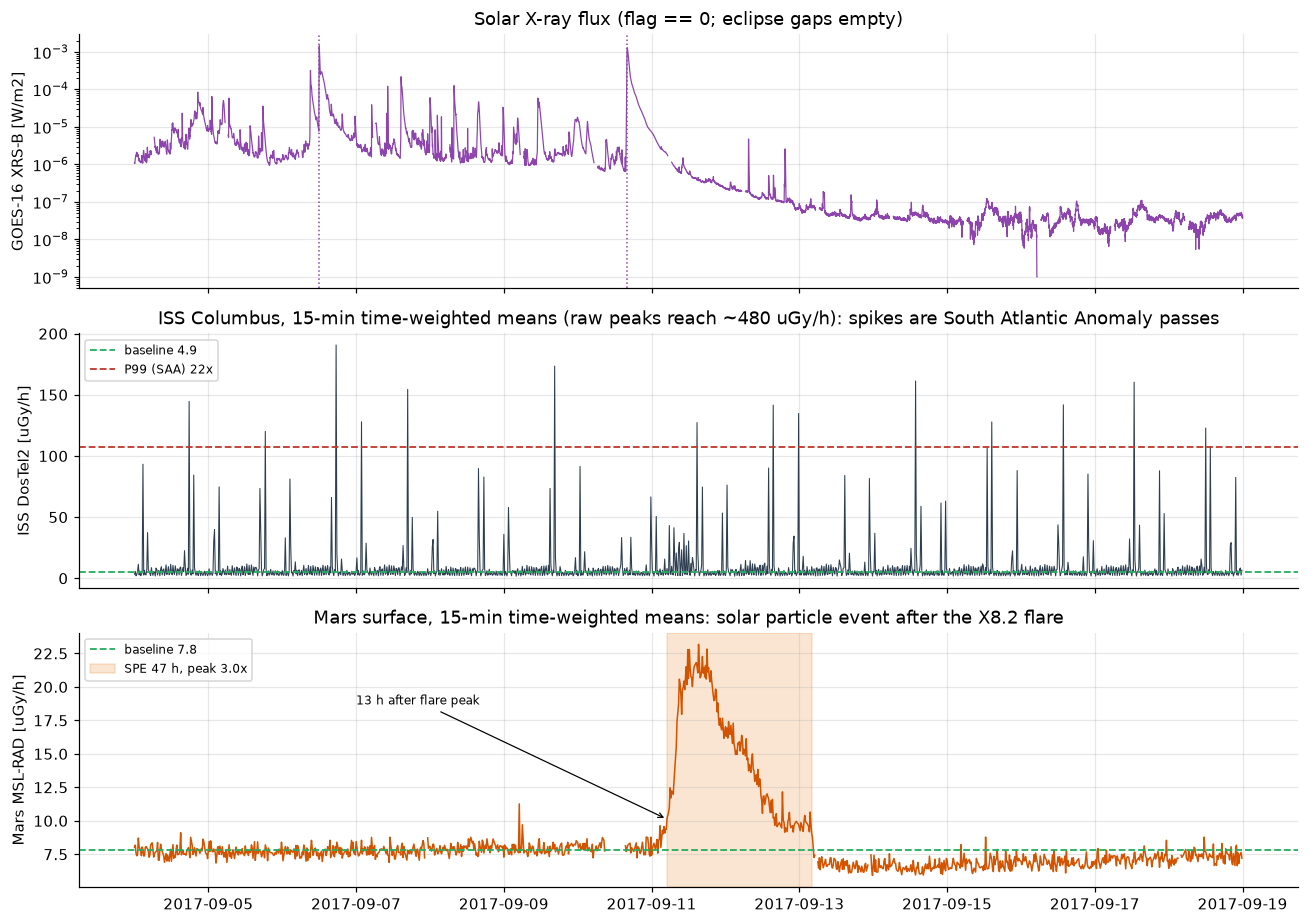

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True)
ax = axes[0]
ax.semilogy(goes.index, goes.values, color="#8e44ad", lw=0.8)
for t in (pd.Timestamp("2017-09-06 12:02"), flare_peak_t):
    ax.axvline(t, color="#8e44ad", ls=":", lw=1)
ax.set(ylabel="GOES-16 XRS-B [W/m2]", title="Solar X-ray flux (flag == 0; eclipse gaps empty)")
ax = axes[1]
ax.plot(dos.index, dos.values, color="#2c3e50", lw=0.7)
ax.axhline(iss_base, color="#27ae60", ls="--", lw=1.2, label=f"baseline {iss_base:.1f}")
ax.axhline(dos.quantile(0.99), color="#c0392b", ls="--", lw=1.2,
           label=f"P99 (SAA) {dos.quantile(0.99) / iss_base:.0f}x")
ax.set(ylabel="ISS DosTel2 [uGy/h]",
       title="ISS Columbus, 15-min time-weighted means (raw peaks reach ~480 uGy/h): "
             "spikes are South Atlantic Anomaly passes")
ax.legend(loc="upper left", fontsize=8)
ax = axes[2]
ax.plot(msl.index, msl.values, color="#d35400", lw=1)
ax.axhline(mars_base, color="#27ae60", ls="--", lw=1.2, label=f"baseline {mars_base:.1f}")
ax.axvspan(spe_on, spe_off, color="#e67e22", alpha=0.2,
           label=f"SPE {a2['spe_duration_h']:.0f} h, peak {a2['spe_peak_multiple']:.1f}x")
ax.annotate(f"{a2['flare_peak_to_spe_onset_h']:.0f} h after flare peak", xy=(spe_on, mars_base * 1.3),
            xytext=(pd.Timestamp("2017-09-07"), mars_base * 2.4), fontsize=8,
            arrowprops={"arrowstyle": "->", "lw": 0.8})
ax.set(ylabel="Mars MSL-RAD [uGy/h]",
       title="Mars surface, 15-min time-weighted means: solar particle event after the X8.2 flare")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "A2_radiation_dose_and_flares.png")

## A3 Heart rate and HRV under stress vs relaxation (WESAD S2-S5, chest ECG)

One HR / RMSSD value per minute (from `physio_replay.py --build`). Relaxation = baseline +
meditation (amusement excluded: it raises arousal). Regression with a fixed effect per
subject, so each person is compared with themself:

- `HR = a_subject + b * stress`
- `log(RMSSD) = a_subject + c * stress`  -> stress multiplies RMSSD by `exp(c)`

Minutes within one segment are not independent, so the standard errors are optimistic;
the effect sizes are what the engine uses. Fluctuation = SD of minute values around each
segment's mean (the real wiggle the state model overlays).

In [7]:
frame = pr.PhysioReplay.load().frame
data = frame[frame["condition"].isin(["baseline", "meditation", "stress"])].copy()
data["stress"] = (data["condition"] == "stress").astype(float)


def fit_fixed_effects(y, df):
    X = pd.get_dummies(df["subject"], dtype=float)
    X["stress"] = df["stress"]
    beta, *_ = np.linalg.lstsq(X.values, y.values, rcond=None)
    resid = y.values - X.values @ beta
    dof = len(y) - X.shape[1]
    cov = (resid @ resid / dof) * np.linalg.inv(X.values.T @ X.values)
    i = list(X.columns).index("stress")
    r2 = 1 - (resid @ resid) / ((y - y.mean()) ** 2).sum()
    return beta[i], np.sqrt(cov[i, i]), r2


b_hr, se_hr, r2_hr = fit_fixed_effects(data["hr"], data)
c_rm, se_rm, r2_rm = fit_fixed_effects(np.log(data["rmssd"]), data)

seg_mean = data.groupby(["subject", "segment_id"])[["hr", "rmssd"]].transform("mean")
data["hr_dev"] = data["hr"] - seg_mean["hr"]
data["rmssd_dev_rel"] = data["rmssd"] / seg_mean["rmssd"] - 1
group = np.where(data["stress"] == 1, "stress", "relax")
fluct = data.groupby(group)[["hr_dev", "rmssd_dev_rel"]].std()
base = frame[frame["condition"] == "baseline"].groupby("subject")[["hr", "rmssd"]].mean()

a3 = {
    "minutes": {k: int(v) for k, v in data["condition"].value_counts().items()},
    "stress_hr_delta_bpm": round(b_hr, 1),
    "stress_hr_delta_95ci": [round(b_hr - 1.96 * se_hr, 1), round(b_hr + 1.96 * se_hr, 1)],
    "stress_rmssd_ratio": round(float(np.exp(c_rm)), 3),
    "stress_rmssd_ratio_95ci": [round(float(np.exp(c_rm - 1.96 * se_rm)), 3),
                                round(float(np.exp(c_rm + 1.96 * se_rm)), 3)],
    "r2_hr_log_rmssd": [round(r2_hr, 2), round(r2_rm, 2)],
    "hr_fluct_sd_bpm": {k: round(v, 2) for k, v in fluct["hr_dev"].items()},
    "rmssd_fluct_cv": {k: round(v, 3) for k, v in fluct["rmssd_dev_rel"].items()},
    "baseline_hr_by_subject": base["hr"].round(1).to_dict(),
    "baseline_rmssd_by_subject": base["rmssd"].round(1).to_dict(),
}
RESULTS["A3"] = a3
a3

{'minutes': {'baseline': 76, 'meditation': 48, 'stress': 40},
 'stress_hr_delta_bpm': np.float64(21.7),
 'stress_hr_delta_95ci': [np.float64(19.3), np.float64(24.0)],
 'stress_rmssd_ratio': 0.512,
 'stress_rmssd_ratio_95ci': [0.476, 0.551],
 'r2_hr_log_rmssd': [np.float64(0.71), np.float64(0.87)],
 'hr_fluct_sd_bpm': {'relax': 2.6, 'stress': 7.24},
 'rmssd_fluct_cv': {'relax': 0.136, 'stress': 0.211},
 'baseline_hr_by_subject': {'S2': 72.7, 'S3': 54.2, 'S4': 60.8, 'S5': 62.7},
 'baseline_rmssd_by_subject': {'S2': 54.9,
  'S3': 101.4,
  'S4': 80.7,
  'S5': 30.1}}

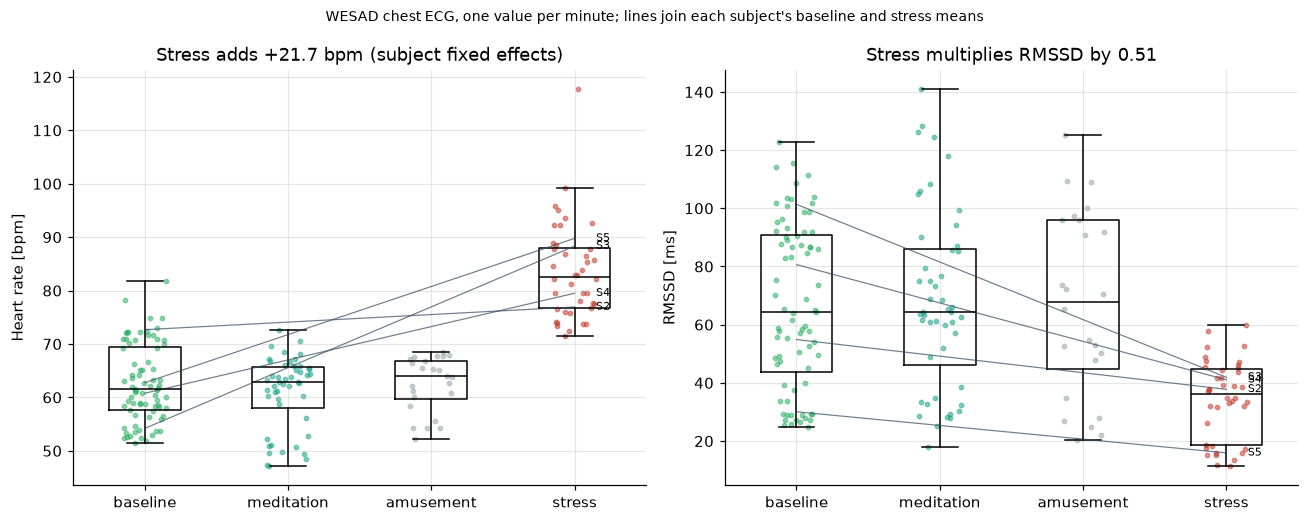

In [8]:
order = ["baseline", "meditation", "amusement", "stress"]
colors = {"baseline": "#27ae60", "meditation": "#16a085", "amusement": "#95a5a6", "stress": "#c0392b"}
means = frame.groupby(["subject", "condition"])[["hr", "rmssd"]].mean().unstack()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, col, label in ((axes[0], "hr", "Heart rate [bpm]"), (axes[1], "rmssd", "RMSSD [ms]")):
    ax.boxplot([frame.loc[frame["condition"] == c, col] for c in order], tick_labels=order,
               widths=0.5, showfliers=False, medianprops={"color": "black"})
    for i, c in enumerate(order, 1):
        vals = frame.loc[frame["condition"] == c, col]
        jitter = np.random.default_rng(config.RANDOM_SEED).uniform(-0.15, 0.15, len(vals))
        ax.scatter(i + jitter, vals, s=8, alpha=0.5, color=colors[c])
    for subj, row in means[col].iterrows():
        ax.plot([1, 4], [row["baseline"], row["stress"]], color="#34495e", lw=0.8, alpha=0.7)
        ax.text(4.15, row["stress"], subj, fontsize=7, va="center")
    ax.set(ylabel=label)
axes[0].set_title(f"Stress adds {b_hr:+.1f} bpm (subject fixed effects)")
axes[1].set_title(f"Stress multiplies RMSSD by {np.exp(c_rm):.2f}")
fig.suptitle("WESAD chest ECG, one value per minute; lines join each subject's baseline and stress means",
             fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "A3_wesad_stress_hr_hrv.png")

## A4 Pre- and post-flight blood and clinical values (Inspiration4, 4 civilian crew)

CMP (OSD-575) and CBC (OSD-569) via `data/mappings/clinical_timepoints.yaml`. The urine
immune panel (OSD-656) is in relative NPQ units with no reference range, so it is not used
for baselines.

- **Synthetic baseline ranges**: min-max of all pre-flight values (L-92, L-44, L-3) across
  the crew, for the analytes the twin uses (glucose, hemoglobin) plus context analytes.
- **Post-flight change**: per crew member, R+1 vs their own pre-flight mean; median across
  crew. Only 4 people and a 3-day flight: this sets what to watch and plausible ranges,
  not individual thresholds (plan 2.4).

Data issues handled here:
- C003 platelet count at L-92 is 12.9 x10^3/uL while their other six timepoints are
  185-396: a recording error (likely a lost digit). It is excluded (`EXCLUDE` below).
- The R+45 samples of C002, C003 and C004 show the classic signature of delayed processing:
  glucose 36-44 mg/dL (far below every other visit; cells keep consuming it) together with
  raised potassium (C004 +46%, C003 +26%; cells leak it). Both analytes of these three
  samples are excluded from the baseline and from every pre/post change figure and
  statement, so no chart suggests flight-induced hypoglycemia or hyperkalemia.

**Limitation (quote as is):** Inspiration4 has only 4 people and a 3-day flight; some other
OSDR data come from mice. These data only decide what to watch and when to check, not individual thresholds.

In [9]:
M = ROOT / "data" / "mappings" / "clinical_timepoints.yaml"
clin = pd.concat([gr.read_source(M, "inspiration4_cmp"), gr.read_source(M, "inspiration4_cbc")],
                 ignore_index=True)
EXCLUDE = [("C003", "L-92", "platelet_count"),    # recording error, see above
           ("C002", "R+45", "GLUCOSE"),           # sample-handling artifacts, see above
           ("C003", "R+45", "GLUCOSE"),
           ("C004", "R+45", "GLUCOSE"),
           ("C002", "R+45", "POTASSIUM"),         # same samples: potassium leak
           ("C003", "R+45", "POTASSIUM"),
           ("C004", "R+45", "POTASSIUM")]
for subj, tp, analyte in EXCLUDE:
    clin = clin[~((clin["subject"] == subj) & (clin["timepoint"] == tp) & (clin["analyte"] == analyte))]
KEY = {"GLUCOSE": "Glucose", "hemoglobin": "Hemoglobin", "hematocrit": "Hematocrit",
       "white_blood_cell_count": "White blood cells", "platelet_count": "Platelets",
       "SODIUM": "Sodium", "POTASSIUM": "Potassium", "CREATININE": "Creatinine"}
key = clin[clin["analyte"].isin(KEY)].copy()
pre = key[key["phase"] == "pre_launch"]
pre_mean = pre.groupby(["analyte", "subject"])["value"].mean()
key["pct_vs_pre"] = (key["value"] / key.set_index(["analyte", "subject"]).index.map(pre_mean) - 1) * 100
units = key.groupby("analyte")["unit"].first()
r1 = key[key["timepoint"] == "R+1"].groupby("analyte")["pct_vs_pre"]
out_of_range = key[(key["value"] < key["range_min"]) | (key["value"] > key["range_max"])]

a4 = {
    "pre_flight_range": {a: [round(pre.loc[pre["analyte"] == a, "value"].min(), 2),
                             round(pre.loc[pre["analyte"] == a, "value"].max(), 2), units[a]]
                         for a in KEY},
    "r1_pct_change_median": {a: round(r1.median()[a], 1) for a in KEY},
    "r1_pct_change_min_max": {a: [round(r1.min()[a], 1), round(r1.max()[a], 1)] for a in KEY},
    "out_of_reference_range_rows": {a: int(n) for a, n in out_of_range["analyte"].value_counts().items()},
    "excluded_points": [list(x) for x in EXCLUDE],
}
RESULTS["A4"] = a4
a4

{'pre_flight_range': {'GLUCOSE': [np.float64(56.0),
   np.float64(100.0),
   'mg/dL'],
  'hemoglobin': [np.float64(11.5), np.float64(17.0), 'g/dL'],
  'hematocrit': [np.float64(35.9), np.float64(50.0), '%'],
  'white_blood_cell_count': [np.float64(5.4), np.float64(10.6), '10^3/uL'],
  'platelet_count': [np.float64(227.0), np.float64(367.0), '10^3/uL'],
  'SODIUM': [np.float64(138.0), np.float64(143.0), 'mmol/L'],
  'POTASSIUM': [np.float64(3.3), np.float64(4.6), 'mmol/L'],
  'CREATININE': [np.float64(0.83), np.float64(1.37), 'mg/dL']},
 'r1_pct_change_median': {'GLUCOSE': np.float64(19.1),
  'hemoglobin': np.float64(-1.4),
  'hematocrit': np.float64(-1.6),
  'white_blood_cell_count': np.float64(-14.9),
  'platelet_count': np.float64(-2.3),
  'SODIUM': np.float64(-1.5),
  'POTASSIUM': np.float64(-5.5),
  'CREATININE': np.float64(-3.2)},
 'r1_pct_change_min_max': {'GLUCOSE': [np.float64(13.7), np.float64(44.4)],
  'hemoglobin': [np.float64(-3.2), np.float64(0.9)],
  'hematocrit': [np.flo

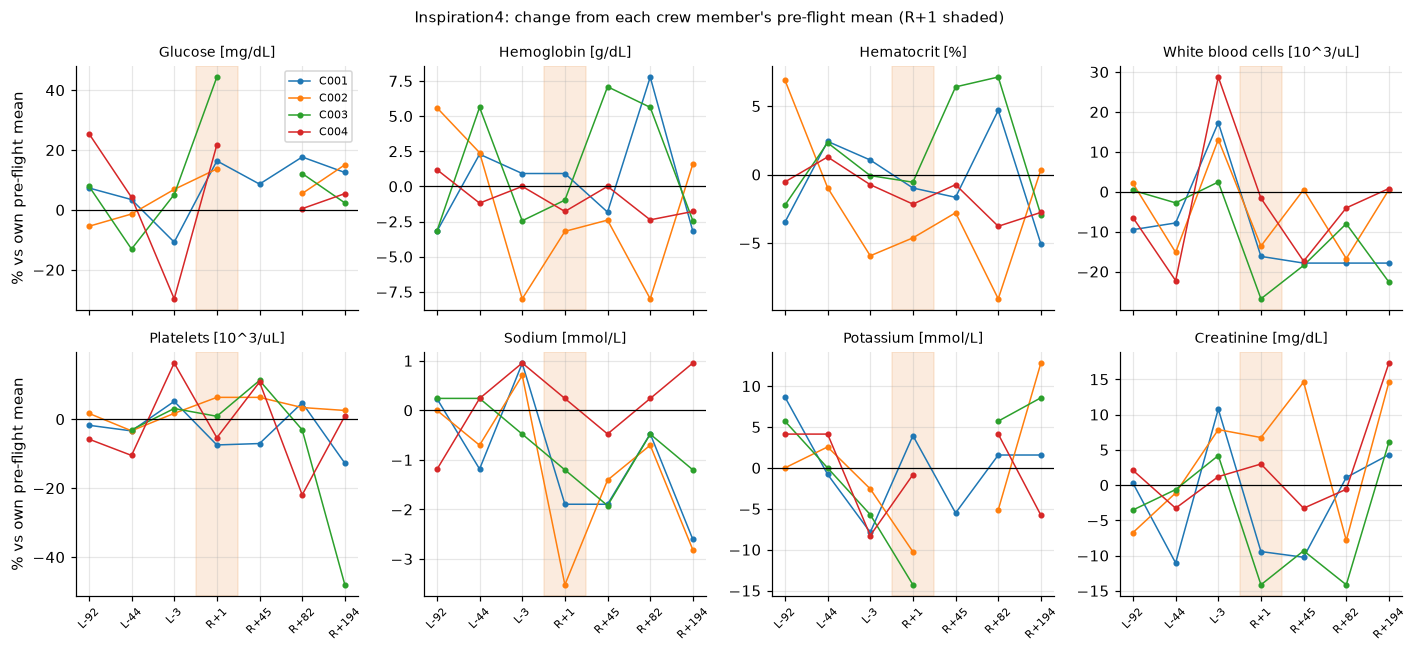

In [10]:
tp_order = ["L-92", "L-44", "L-3", "R+1", "R+45", "R+82", "R+194"]
fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharex=True)
for ax, (analyte, label) in zip(axes.flat, KEY.items()):
    sub = key[key["analyte"] == analyte]
    for subj, g in sub.groupby("subject"):
        g = g.set_index("timepoint").reindex(tp_order)
        ax.plot(range(len(tp_order)), g["pct_vs_pre"], marker="o", ms=3, lw=1, label=subj)
    ax.axhline(0, color="black", lw=0.8)
    ax.axvspan(2.5, 3.5, color="#e67e22", alpha=0.15)
    ax.set_title(f"{label} [{units[analyte]}]", fontsize=9)
    ax.set_xticks(range(len(tp_order)), tp_order, rotation=45, fontsize=7)
for ax in axes[:, 0]:
    ax.set_ylabel("% vs own pre-flight mean")
axes[0, 0].legend(fontsize=7)
fig.suptitle("Inspiration4: change from each crew member's pre-flight mean (R+1 shaded)", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "A4_inspiration4_clinical_changes.png")

## Daily occurrence of operators B and D (probability track)

The probability track draws each operator independently with the probability that it
happens on a given day (plan 3.7: unbiased sampling by the real distribution).

- **B, cabin CO2 build-up**: share of A1 days whose 15-minute CO2 peak goes above the
  high-CO2 level (A1 P90).
- **D, solar particle event**: NOAA SWPC list of solar proton events affecting the Earth
  environment (>10 MeV protons reaching 10 pfu at GOES), 1976-2017, i.e. four full solar
  cycles; events per day = chance that an event starts on a given day. Earth-orbit data
  used as a proxy for Mars (no global magnetic field there; the rate of solar events is
  the same Sun, the dose differs).

In [11]:
import re
a1["high_co2_day_share"] = round(float((by_day.max() > co2_high).mean()), 3)
a1["high_co2_days"] = [int((by_day.max() > co2_high).sum()), int(by_day.ngroups)]
a1["co2_max_ppm_15min"] = int(round(co2.max()))
RESULTS["A1"] = a1

html = (ROOT / "data" / "raw" / "noaa_spe" / "sep_list.html").read_text(encoding="latin-1")
year, per_year = None, {}
for row in html.split("<tr>")[1:]:
    y = re.search(r"<strong>(\d{4})</strong>", row)
    if y:
        year = int(y.group(1)); per_year.setdefault(year, 0); continue
    if year and re.match(r"\s*<td>[A-Z][a-z]{2} \d{2}/\d{4}", row):
        per_year[year] += 1
years = [y for y in sorted(per_year) if 1976 <= y <= 2017]
n_events = sum(per_year[y] for y in years)
n_days = sum(366 if pd.Timestamp(year=y, month=12, day=31).dayofyear == 366 else 365 for y in years)
a2["spe_events_1976_2017"] = n_events
a2["spe_years"] = [years[0], years[-1]]
a2["spe_per_year_mean_max"] = [round(n_events / len(years), 2), max(per_year[y] for y in years)]
a2["spe_years_without_event"] = sum(per_year[y] == 0 for y in years)
a2["spe_daily_onset_prob"] = round(n_events / n_days, 4)
RESULTS["A2"] = a2
{"B": a1["high_co2_day_share"], "D": a2["spe_daily_onset_prob"], "per_year": per_year}

/var/folders/yk/h9twqd357rd0nl5h_q2n97300000gn/T/ipykernel_96721/2196119130.py:17: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  n_days = sum(366 if pd.Timestamp(year=y, month=12, day=31).dayofyear == 366 else 365 for y in years)


{'B': 0.382,
 'D': 0.017,
 'per_year': {1976: 1,
  1977: 2,
  1978: 9,
  1979: 7,
  1980: 2,
  1981: 10,
  1982: 12,
  1983: 2,
  1984: 7,
  1985: 3,
  1986: 4,
  1987: 1,
  1988: 9,
  1989: 23,
  1990: 12,
  1991: 17,
  1992: 6,
  1993: 2,
  1994: 2,
  1995: 1,
  1996: 0,
  1997: 2,
  1998: 8,
  1999: 5,
  2000: 13,
  2001: 21,
  2002: 19,
  2003: 9,
  2004: 5,
  2005: 7,
  2006: 2,
  2007: 0,
  2008: 0,
  2009: 0,
  2010: 1,
  2011: 7,
  2012: 13,
  2013: 4,
  2014: 6,
  2015: 4,
  2016: 0,
  2017: 3}}

## A6 Convergence: how many probability-track samples are enough

Five independent runs (seeds 147-151) of 5,000 probability-track samples each, for the
main plan and the safe day; the running estimate after n samples is the risk the engine
would report with N = n. N must separate the rating lines: the 95% confidence half-width
must be at most `config.A6_HALF_WIDTH` at the 1% (green / yellow) and 5% (yellow / red)
lines. Required n = z^2 p (1 - p) / h^2, rounded up to a multiple of 500.

In [12]:
import dataclasses
import math
from spacefuzz.fuzzing import engine as en
from spacefuzz.core import evaluator as ev
from spacefuzz.core import model as md
from spacefuzz.fuzzing import mutator as mu
from spacefuzz.core import state as st

B = st.make_baseline()
FL = md.Fluctuation.from_wesad()
SCEN = {n: mu.Scenario.load(n) for n in ["main_sleep_debt_eva", "safe_day", "rule2_violation",
                                         "backup_high_co2", "radiation_spe"]}
DAILY = {"MUT_DAILY_PROB": dict(config.PROB_OPERATOR_DAILY)}

def crash_flags(name, n, seed):
    m = mu.Mutator(SCEN[name], B, seed=seed, fluctuation=FL, params=DAILY)
    return np.array([ev.evaluate(r.output, r.sample.plan, r.sample.checkin, B).crashed
                     for r in m.generate(n)], dtype=float)

A6_SEEDS = [config.RANDOM_SEED + k for k in range(5)]
A6_NMAX = 5000
A6_GRID = [250, 500, 1000, 2500, 5000]
flags = {name: {s: crash_flags(name, A6_NMAX, s) for s in A6_SEEDS}
         for name in ["main_sleep_debt_eva", "safe_day"]}
need = {p: math.ceil(1.96 ** 2 * p * (1 - p) / h ** 2) for p, h in config.A6_HALF_WIDTH.items()}
n_chosen = int(math.ceil(max(need.values()) / 500) * 500)
a6 = {
    "required_n_at": {f"{p:.0%}": n for p, n in need.items()},
    "n_chosen": n_chosen,
    "risk_by_seed_at_n": {name: {str(n): [round(float(f[:n].mean()), 4) for f in fl.values()]
                                 for n in A6_GRID} for name, fl in flags.items()},
    "seed_sd_pct_points_at_n": {name: {str(n): round(float(np.std([f[:n].mean() for f in fl.values()],
                                                                   ddof=1)) * 100, 2)
                                       for n in A6_GRID} for name, fl in flags.items()},
}
RESULTS["A6"] = a6
a6

{'required_n_at': {'1%': 2377, '5%': 1825},
 'n_chosen': 2500,
 'risk_by_seed_at_n': {'main_sleep_debt_eva': {'250': [0.208,
    0.192,
    0.196,
    0.196,
    0.2],
   '500': [0.204, 0.186, 0.224, 0.186, 0.224],
   '1000': [0.214, 0.197, 0.209, 0.199, 0.215],
   '2500': [0.2096, 0.1936, 0.2116, 0.1984, 0.2112],
   '5000': [0.2116, 0.1972, 0.2158, 0.1936, 0.2074]},
  'safe_day': {'250': [0.008, 0.012, 0.008, 0.004, 0.004],
   '500': [0.008, 0.008, 0.01, 0.004, 0.008],
   '1000': [0.012, 0.011, 0.009, 0.009, 0.007],
   '2500': [0.0132, 0.0068, 0.0084, 0.0088, 0.0076],
   '5000': [0.0124, 0.009, 0.0096, 0.007, 0.0094]}},
 'seed_sd_pct_points_at_n': {'main_sleep_debt_eva': {'250': 0.61,
   '500': 1.9,
   '1000': 0.84,
   '2500': 0.83,
   '5000': 0.94},
  'safe_day': {'250': 0.33,
   '500': 0.22,
   '1000': 0.19,
   '2500': 0.25,
   '5000': 0.19}}}

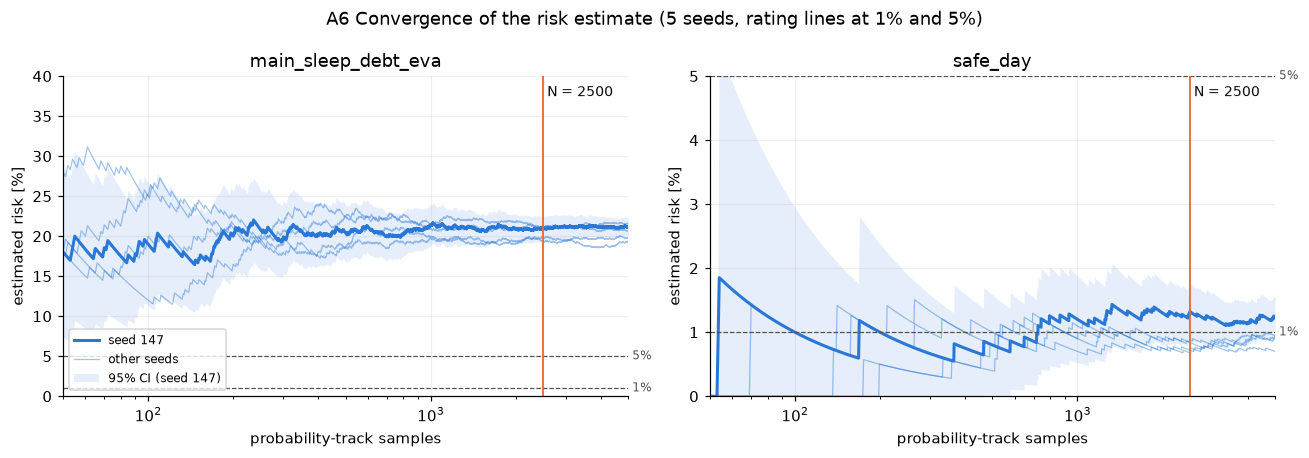

In [13]:
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (name, fl) in zip(axes, flags.items()):
    n = np.arange(1, A6_NMAX + 1)
    for k, (seed, f) in enumerate(fl.items()):
        run = np.cumsum(f) / n
        ax.plot(n, run * 100, color=BLUE, lw=2 if k == 0 else 0.8, alpha=1 if k == 0 else 0.45,
                label=f"seed {seed}" if k == 0 else ("other seeds" if k == 1 else None))
    p = np.cumsum(fl[A6_SEEDS[0]]) / n
    half = 1.96 * np.sqrt(np.clip(p * (1 - p), 1e-9, None) / n)
    ax.fill_between(n, np.clip(p - half, 0, None) * 100, (p + half) * 100, color=BLUE, alpha=0.12, lw=0,
                    label="95% CI (seed 147)")
    for line in (1, 5):
        ax.axhline(line, color="#52514e", lw=0.8, ls="--")
        ax.text(A6_NMAX, line, f" {line}%", va="center", fontsize=8, color="#52514e")
    top = 40 if name.startswith("main") else 5
    ax.axvline(n_chosen, color=ORANGE, lw=1.2)
    ax.text(n_chosen, top * 0.97, f" N = {n_chosen}", color="#0b0b0b", fontsize=9, va="top")
    ax.set(xscale="log", xlim=(50, A6_NMAX), ylim=(0, top), xlabel="probability-track samples",
           ylabel="estimated risk [%]", title=name)
    ax.grid(alpha=0.2)
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("A6 Convergence of the risk estimate (5 seeds, rating lines at 1% and 5%)")
fig.tight_layout()
fig.savefig(FIG / "A6_convergence.png", dpi=150)
plt.show()

## A7 Guided track vs pure random: samples needed to find each crash type

Same plan, same simulator, three ways to search, 2,000 simulations each, 3 seeds:
- **guided**: the guided track (mutates the seed closest to a crash);
- **random mutation**: the same 1-3 stacked operators, always from the real day (no guidance);
- **Monte Carlo**: the probability track's unbiased daily sampling.

For each crash type (system / rule) the number of simulations until it is first found;
median over seeds; "not found" = not found within 2,000 in at least 2 of 3 seeds.

In [14]:
A7_ROUNDS, A7_SEEDS = 2000, [config.RANDOM_SEED + k for k in range(3)]

def first_found(name, seed, params):
    m = mu.Mutator(SCEN[name], B, seed=seed, fluctuation=FL, params=params)
    first = {}
    for i in range(1, A7_ROUNDS + 1):
        smp = m.draw()
        out = m.simulate(smp)
        if mu.check_chains(out, m.reference, [o.op for o in smp.ops]):
            continue
        for v in ev.evaluate(out, smp.plan, smp.checkin, B).violations:
            first.setdefault(f"{v.system}/{v.rule}", i)
    return first

def first_guided(name, seed):
    g = en.guided_track(SCEN[name], B, A7_ROUNDS, seed=seed, fluctuation=FL)
    return {f"{c['system']}/{c['rule']}": c["first_round"] for c in g["crash_types"]}

a7 = {}
for name in ["main_sleep_debt_eva", "safe_day"]:
    runs = {"guided": [first_guided(name, s) for s in A7_SEEDS],
            "random mutation": [first_found(name, s, {}) for s in A7_SEEDS],
            "Monte Carlo": [first_found(name, s, DAILY) for s in A7_SEEDS]}
    types = sorted({t for rs in runs.values() for r in rs for t in r})
    table = {}
    for t in types:
        row = {}
        for method, rs in runs.items():
            found = [r[t] for r in rs if t in r]
            row[method] = int(np.median(found)) if len(found) >= 2 else None
        table[t] = row
    a7[name] = {"sims_to_first_find_median": table,
                "types_found": {m: sum(v[m] is not None for v in table.values()) for m in runs}}
RESULTS["A7"] = a7
a7

{'main_sleep_debt_eva': {'sims_to_first_find_median': {'CNS/cognitive': {'guided': 5,
    'random mutation': 23,
    'Monte Carlo': 13},
   'CNS/rule3_co2_precision': {'guided': 123,
    'random mutation': None,
    'Monte Carlo': None},
   'Cardiovascular/cardiovascular': {'guided': 3,
    'random mutation': 2,
    'Monte Carlo': 2},
   'Cardiovascular/rule1_sleep_eva': {'guided': 1,
    'random mutation': 1,
    'Monte Carlo': None},
   'Radiation/radiation_dose': {'guided': 59,
    'random mutation': 19,
    'Monte Carlo': 374},
   'Radiation/rule4_spe_eva': {'guided': 14,
    'random mutation': 14,
    'Monte Carlo': 143}},
  'types_found': {'guided': 6, 'random mutation': 5, 'Monte Carlo': 4}},
 'safe_day': {'sims_to_first_find_median': {'CNS/cognitive': {'guided': 6,
    'random mutation': 85,
    'Monte Carlo': 768},
   'CNS/rule3_co2_precision': {'guided': 18,
    'random mutation': None,
    'Monte Carlo': None},
   'Cardiovascular/cardiovascular': {'guided': 3,
    'random mu

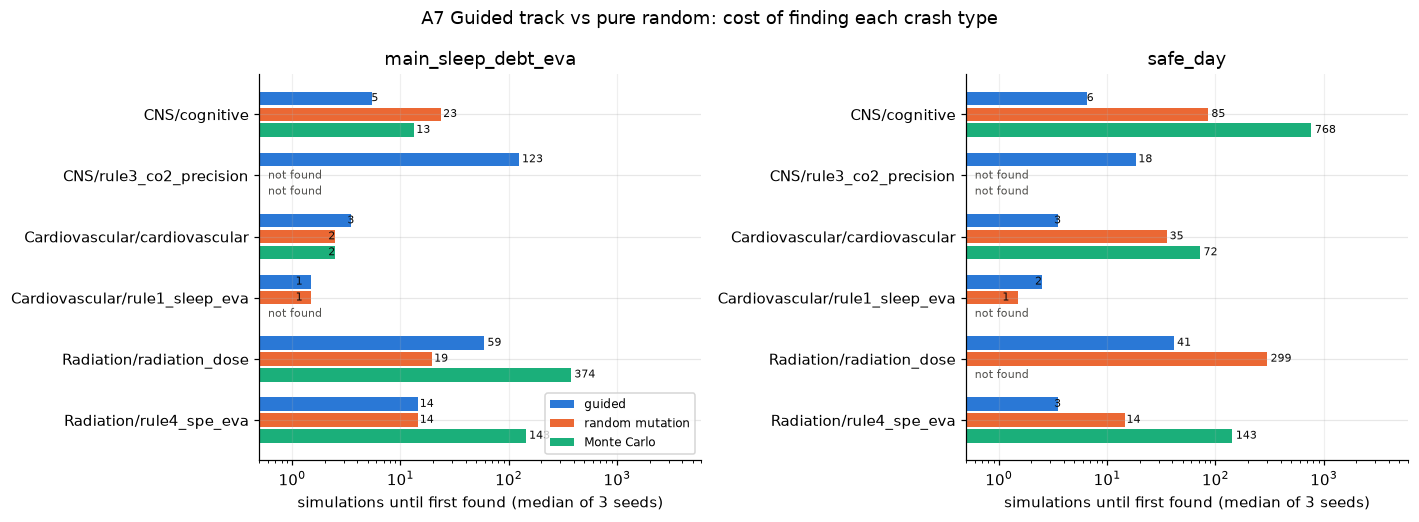

In [15]:
METHODS = [("guided", BLUE), ("random mutation", ORANGE), ("Monte Carlo", AQUA)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (name, res) in zip(axes, a7.items()):
    table = res["sims_to_first_find_median"]
    types = list(table)
    y = np.arange(len(types))
    h = 0.26
    for k, (m, color) in enumerate(METHODS):
        vals = [table[t][m] for t in types]
        for yi, v in zip(y, vals):
            pos = yi + (k - 1) * h
            if v is None:
                ax.text(0.6, pos, "not found", va="center", fontsize=7, color="#52514e")
            else:
                ax.barh(pos, v, left=0.5, height=h - 0.04, color=color, label=m if yi == y[0] else None)
                ax.text(v * 1.08, pos, str(v), va="center", fontsize=7, color="#0b0b0b")
    ax.set(xscale="log", xlim=(0.5, A7_ROUNDS * 3), yticks=y, yticklabels=types,
           xlabel="simulations until first found (median of 3 seeds)", title=name)
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.2)
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle("A7 Guided track vs pure random: cost of finding each crash type")
fig.tight_layout()
fig.savefig(FIG / "A7_guided_vs_random.png", dpi=150)
plt.show()

## A9 Threshold sensitivity: does the ranking survive +-10-20%?

Each rule threshold in `config.py` is moved to 0.8x, 0.9x, 1.1x and 1.2x, one at a time;
all five sample plans are re-forecast with 500 probability-track samples (the same
random numbers each time). Checked: the ranking of plans by risk ("which plan is most
dangerous", Kendall tau-b against the unchanged thresholds) and the main plan's leading
rule ("what to fix first").

In [16]:
from scipy.stats import kendalltau
A9_THRESHOLDS = ["COG_FATIGUE_ABOVE", "COG_SPO2_BELOW_PCT", "CARDIO_HR_MAX_FRACTION",
                 "CARDIO_HRV_RATIO", "METAB_PRE_EVA_GLUCOSE_MG_DL", "METAB_EVA_FALL_MG_DL",
                 "RAD_EVA_DOSE_LIMIT_UGY", "RULE1_MIN_SLEEP_H", "RULE1_WINDOW_H", "RULE2_GAP_H",
                 "RULE3_MAX_WORK_H", "RULE3_CO2_PPM"]
A9_FACTORS, A9_N = [0.8, 0.9, 1.1, 1.2], 500
PLAN_ORDER = list(SCEN)

def forecast_all():
    out = {}
    for n in PLAN_ORDER:
        p = en.probability_track(SCEN[n], B, A9_N, fluctuation=FL)
        out[n] = (p["risk_probability"], max(p["by_rule"], key=p["by_rule"].get) if p["by_rule"] else None)
    return out

base9 = forecast_all()
rows = []
for name in A9_THRESHOLDS:
    orig = getattr(config, name)
    for f in A9_FACTORS:
        setattr(config, name, orig * f)
        try:
            r = forecast_all()
        finally:
            setattr(config, name, orig)
        tau = kendalltau([base9[n][0] for n in PLAN_ORDER], [r[n][0] for n in PLAN_ORDER]).statistic
        rows.append({"threshold": name, "factor": f, "tau": round(float(tau), 3),
                     "main_risk": r["main_sleep_debt_eva"][0], "main_top_rule": r["main_sleep_debt_eva"][1],
                     "main_above_safe": r["main_sleep_debt_eva"][0] > r["safe_day"][0]})
a9_df = pd.DataFrame(rows)
a9 = {
    "base_risk": {n: v[0] for n, v in base9.items()},
    "base_main_top_rule": base9["main_sleep_debt_eva"][1],
    "kendall_tau_min_median": [float(a9_df["tau"].min()), float(a9_df["tau"].median())],
    "share_tau_ge_0_8": round(float((a9_df["tau"] >= 0.8).mean()), 3),
    "share_main_top_rule_unchanged": round(float(
        (a9_df["main_top_rule"] == base9["main_sleep_debt_eva"][1]).mean()), 3),
    "share_main_above_safe": round(float(a9_df["main_above_safe"].mean()), 3),
    "lowest_tau": a9_df.nsmallest(3, "tau")[["threshold", "factor", "tau"]].to_dict("records"),
    "main_risk_range": [float(a9_df["main_risk"].min()), float(a9_df["main_risk"].max())],
}
RESULTS["A9"] = a9
a9

{'base_risk': {'main_sleep_debt_eva': 0.204,
  'safe_day': 0.008,
  'rule2_violation': 1.0,
  'backup_high_co2': 1.0,
  'radiation_spe': 1.0},
 'base_main_top_rule': 'cardiovascular',
 'kendall_tau_min_median': [0.756, 1.0],
 'share_tau_ge_0_8': 0.917,
 'share_main_top_rule_unchanged': 0.896,
 'share_main_above_safe': 1.0,
 'lowest_tau': [{'threshold': 'CARDIO_HR_MAX_FRACTION',
   'factor': 0.8,
   'tau': 0.756},
  {'threshold': 'CARDIO_HR_MAX_FRACTION', 'factor': 0.9, 'tau': 0.756},
  {'threshold': 'RULE1_MIN_SLEEP_H', 'factor': 1.1, 'tau': 0.756}],
 'main_risk_range': [0.016, 1.0]}

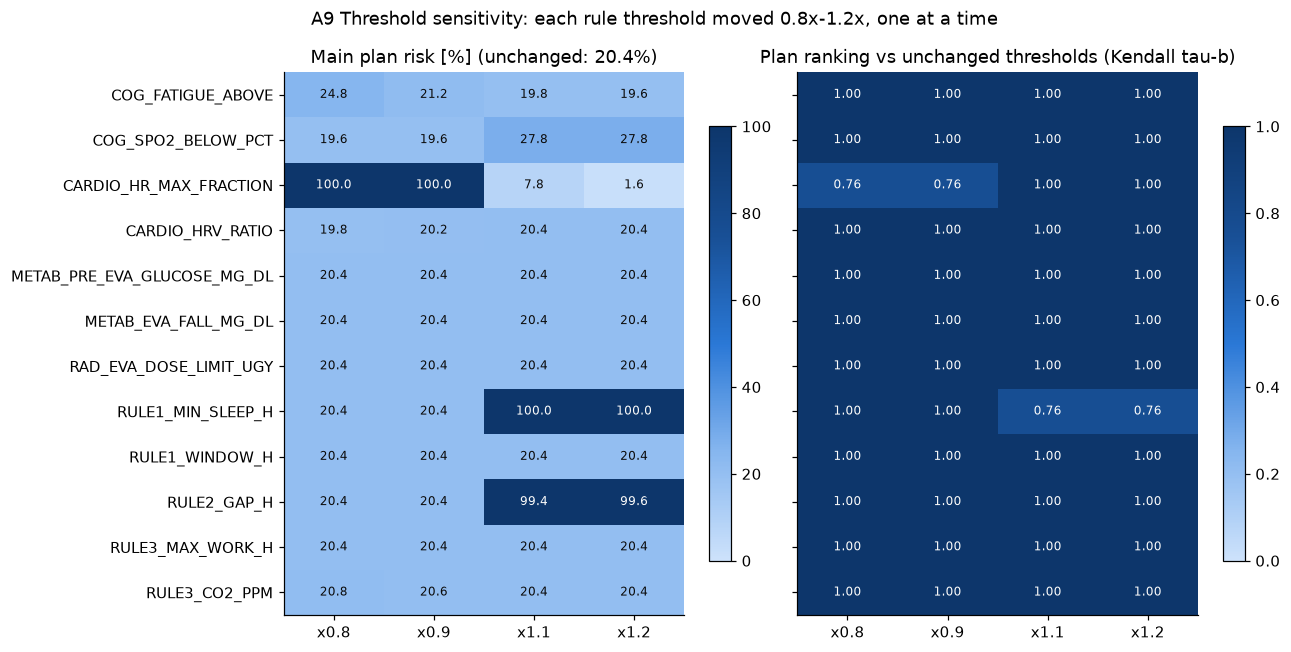

In [17]:
from matplotlib.colors import LinearSegmentedColormap
blues = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
risk_grid = a9_df.pivot(index="threshold", columns="factor", values="main_risk").loc[A9_THRESHOLDS] * 100
tau_grid = a9_df.pivot(index="threshold", columns="factor", values="tau").loc[A9_THRESHOLDS]
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, grid, title, fmt, cmap, vmin, vmax in (
        (axes[0], risk_grid, "Main plan risk [%] (unchanged: "
         f"{a9['base_risk']['main_sleep_debt_eva'] * 100:.1f}%)", "{:.1f}", blues, 0, None),
        (axes[1], tau_grid, "Plan ranking vs unchanged thresholds (Kendall tau-b)", "{:.2f}",
         blues, 0, 1)):
    im = ax.imshow(grid.values, cmap=cmap, aspect="auto", vmin=vmin, vmax=vmax)
    ax.grid(False)
    ax.set(xticks=range(len(A9_FACTORS)), xticklabels=[f"x{f}" for f in A9_FACTORS],
           yticks=range(len(A9_THRESHOLDS)), yticklabels=A9_THRESHOLDS, title=title)
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            v = grid.values[i, j]
            dark = v > (np.nanmax(grid.values) * 0.55 if vmax is None else 0.55)
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8,
                    color="#fcfcfb" if dark else "#0b0b0b")
    fig.colorbar(im, ax=ax, shrink=0.8)
axes[1].set_yticklabels([])
fig.suptitle("A9 Threshold sensitivity: each rule threshold moved 0.8x-1.2x, one at a time")
fig.tight_layout()
fig.savefig(FIG / "A9_threshold_sensitivity.png", dpi=150)
plt.show()

### A9b Does the adjustment still help when the thresholds move?

"Reliable: the ranking and the change before vs after adjustment." The first half is the
ranking above. For the second half, the main plan as written and the plan the adjuster
chose under the default thresholds (shorten the EVA by 2 h, a 1.5 h nap before it, split
it with a 1 h rest; `adjuster.py`, PROGRESS 3.4c) are re-forecast under each of the same
48 threshold variations (500 samples, the same random numbers).

In [18]:
from spacefuzz.fuzzing import adjuster as aj
ADJUSTED = aj._build(SCEN["main_sleep_debt_eva"].plan, [("shorten", 2.0), ("nap", 90), ("split", None)])
adj_scen = dataclasses.replace(SCEN["main_sleep_debt_eva"], plan=ADJUSTED.plan)

def main_pair():
    before = en.probability_track(SCEN["main_sleep_debt_eva"], B, A9_N, fluctuation=FL)["risk_probability"]
    after = en.probability_track(adj_scen, B, A9_N, fluctuation=FL)["risk_probability"]
    return before, after

pairs = [{"threshold": "unchanged", "factor": 1.0, **dict(zip(("before", "after"), main_pair()))}]
for name in A9_THRESHOLDS:
    orig = getattr(config, name)
    for f in A9_FACTORS:
        setattr(config, name, orig * f)
        try:
            b_, a_ = main_pair()
        finally:
            setattr(config, name, orig)
        pairs.append({"threshold": name, "factor": f, "before": b_, "after": a_})
pairs_df = pd.DataFrame(pairs)
var = pairs_df[pairs_df["threshold"] != "unchanged"]
a9b = {
    "adjusted_changes": list(ADJUSTED.changes),
    "unchanged_before_after": [pairs[0]["before"], pairs[0]["after"]],
    "share_after_lower": round(float((var["after"] < var["before"]).mean()), 3),
    "share_after_not_higher": round(float((var["after"] <= var["before"]).mean()), 3),
    "share_after_at_most_5pct": round(float((var["after"] <= config.RISK_RED_ABOVE).mean()), 3),
    "median_reduction_pct_points": round(float((var["before"] - var["after"]).median() * 100), 1),
    "cases_not_lower": var[var["after"] >= var["before"]][["threshold", "factor", "before", "after"]]
        .to_dict("records"),
}
RESULTS["A9"]["adjustment"] = a9b
a9b

{'adjusted_changes': ['Shorten the EVA by 2 h',
  'Insert a 1 h 30 min nap before the EVA',
  'Split the EVA into two parts with a 1 h rest between',
  'EVA now 11:30-13:45, 14:45-17:00'],
 'unchanged_before_after': [0.204, 0.038],
 'share_after_lower': 0.938,
 'share_after_not_higher': 1.0,
 'share_after_at_most_5pct': 0.917,
 'median_reduction_pct_points': 16.6,
 'cases_not_lower': [{'threshold': 'CARDIO_HR_MAX_FRACTION',
   'factor': 0.8,
   'before': 1.0,
   'after': 1.0},
  {'threshold': 'RULE1_MIN_SLEEP_H',
   'factor': 1.1,
   'before': 1.0,
   'after': 1.0},
  {'threshold': 'RULE1_MIN_SLEEP_H',
   'factor': 1.2,
   'before': 1.0,
   'after': 1.0}]}

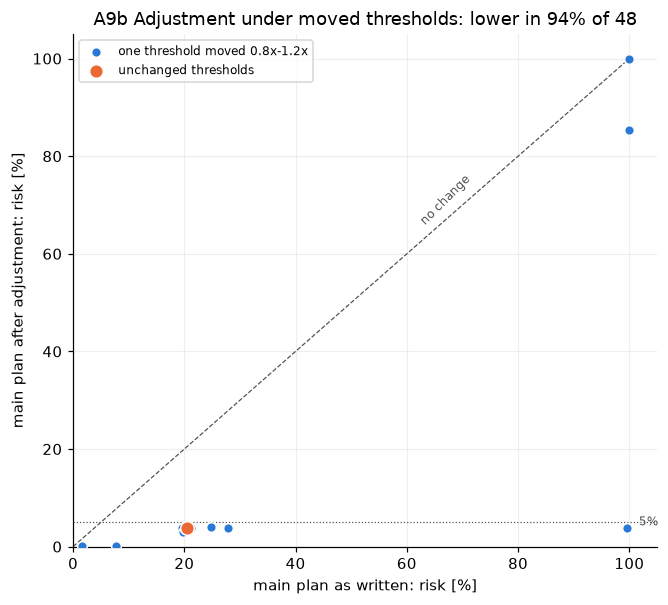

In [19]:
fig, ax = plt.subplots(figsize=(6.2, 5.6))
ax.plot([0, 100], [0, 100], color="#52514e", lw=0.8, ls="--")
ax.text(62, 66, "no change", color="#52514e", fontsize=8, rotation=45)
ax.axhline(config.RISK_RED_ABOVE * 100, color="#52514e", lw=0.8, ls=":")
ax.text(101, config.RISK_RED_ABOVE * 100, " 5%", va="center", fontsize=8, color="#52514e")
ax.scatter(var["before"] * 100, var["after"] * 100, s=40, color=BLUE, edgecolor="#fcfcfb", lw=1,
           label="one threshold moved 0.8x-1.2x", zorder=3)
u = pairs[0]
ax.scatter([u["before"] * 100], [u["after"] * 100], s=80, color=ORANGE, edgecolor="#fcfcfb", lw=1,
           label="unchanged thresholds", zorder=4)
ax.set(xlim=(0, 105), ylim=(0, 105), xlabel="main plan as written: risk [%]",
       ylabel="main plan after adjustment: risk [%]",
       title=f"A9b Adjustment under moved thresholds: lower in {a9b['share_after_lower']:.0%} of 48")
ax.grid(alpha=0.2)
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "A9b_adjustment_under_thresholds.png", dpi=150)
plt.show()

## Constants for `config.py`

The values below are copied into `config.py` (section "Data-derived constants"), each with
a comment naming its analysis. `tests/test_config_analysis.py` checks that config matches
this output (`notebooks/analysis_results.json`).

In [20]:
constants = {
    # A1
    "EDA_ISS_START": str(iss_start),
    "ENV_CO2_HIGH_PPM": a1["co2_high_ppm_p90"],
    "OP_B_CO2_AMPLIFY_RANGE": [a1["daily_peak_excursion_p25_p50_p90"][0],
                               a1["daily_peak_excursion_p25_p50_p90"][2]],
    "OP_B_CO2_AMPLIFY_MAX": a1["daily_peak_excursion_max"],
    "ENV_CO2_MAX_OBSERVED_PPM": a1["co2_max_ppm_15min"],
    "ENV_HIGH_CO2_DAY": a1["high_co2_day"],
    "ENV_TEMP_RANGE_C": a1["temp_c_p05_p95"],
    "ENV_RH_RANGE_PCT": a1["humidity_pct_p05_p95"],
    # A2
    "RAD_BASELINE_ISS_UGY_H": a2["iss_baseline_ugy_h_median"],
    "RAD_BASELINE_MARS_UGY_H": a2["mars_baseline_ugy_h"],
    "OP_D_SAA_PEAK_MULTIPLE": a2["iss_saa_peak_multiple_p99"],
    "OP_D_SPE_PEAK_MULTIPLE": a2["spe_peak_multiple"],
    "OP_D_SPE_DURATION_H": a2["spe_duration_h"],
    "OP_D_FLARE_TO_SPE_ONSET_H": a2["flare_peak_to_spe_onset_h"],
    "OP_B_DAILY_PROB": a1["high_co2_day_share"],
    "OP_D_DAILY_PROB": a2["spe_daily_onset_prob"],
    "GOES_OFFICIAL_SCALE": round(float(np.mean(list(a2["catalog_over_science_flux"].values()))), 3),
    # A3
    "CHAIN1_STRESS_HR_DELTA_BPM": a3["stress_hr_delta_bpm"],
    "CHAIN1_STRESS_RMSSD_RATIO": a3["stress_rmssd_ratio"],
    "PHYSIO_HR_FLUCT_SD_BPM": a3["hr_fluct_sd_bpm"],
    "PHYSIO_RMSSD_FLUCT_CV": a3["rmssd_fluct_cv"],
    "BASELINE_HR_RANGE_BPM": [min(a3["baseline_hr_by_subject"].values()),
                              max(a3["baseline_hr_by_subject"].values())],
    "BASELINE_RMSSD_RANGE_MS": [min(a3["baseline_rmssd_by_subject"].values()),
                                max(a3["baseline_rmssd_by_subject"].values())],
    # A4
    "BASELINE_GLUCOSE_MG_DL_RANGE": a4["pre_flight_range"]["GLUCOSE"][:2],
    "BASELINE_HEMOGLOBIN_G_DL_RANGE": a4["pre_flight_range"]["hemoglobin"][:2],
    "I4_R1_PCT_CHANGE": a4["r1_pct_change_median"],
    # A6
    "PROBABILITY_SAMPLES": a6["n_chosen"],
}
RESULTS["constants"] = constants
(ROOT / "notebooks" / "analysis_results.json").write_text(
    json.dumps(RESULTS, indent=2, default=str) + "\n", encoding="utf-8")
for k, v in constants.items():
    print(f"{k} = {v!r}")

EDA_ISS_START = '2014-09-27 13:30:00'
ENV_CO2_HIGH_PPM = 3997
OP_B_CO2_AMPLIFY_RANGE = [np.float64(0.112), np.float64(0.23)]
OP_B_CO2_AMPLIFY_MAX = np.float64(0.403)
ENV_CO2_MAX_OBSERVED_PPM = 4663
ENV_HIGH_CO2_DAY = '2014-10-07'
ENV_TEMP_RANGE_C = [np.float64(22.1), np.float64(22.9)]
ENV_RH_RANGE_PCT = [np.float64(40.0), np.float64(49.0)]
RAD_BASELINE_ISS_UGY_H = np.float64(4.94)
RAD_BASELINE_MARS_UGY_H = np.float64(7.79)
OP_D_SAA_PEAK_MULTIPLE = np.float64(21.7)
OP_D_SPE_PEAK_MULTIPLE = np.float64(2.98)
OP_D_SPE_DURATION_H = 47.0
OP_D_FLARE_TO_SPE_ONSET_H = 12.9
OP_B_DAILY_PROB = 0.382
OP_D_DAILY_PROB = 0.017
GOES_OFFICIAL_SCALE = 0.635
CHAIN1_STRESS_HR_DELTA_BPM = np.float64(21.7)
CHAIN1_STRESS_RMSSD_RATIO = 0.512
PHYSIO_HR_FLUCT_SD_BPM = {'relax': 2.6, 'stress': 7.24}
PHYSIO_RMSSD_FLUCT_CV = {'relax': 0.136, 'stress': 0.211}
BASELINE_HR_RANGE_BPM = [54.2, 72.7]
BASELINE_RMSSD_RANGE_MS = [30.1, 101.4]
BASELINE_GLUCOSE_MG_DL_RANGE = [np.float64(56.0), np.float64(100.0)]
BASELINE_HEMO